### About the code -

It is a llm based parallel workflow, what different from cricket example is ->
1. llm based
2. structured output
3. reducer used 

we will give a essay and workflow will evaluate it on the basis of clarity of thought, language and depth of analysis. each eval will give a feedback and a score from 1 to 10.

scores will be stored in a list and keeps on adding instead of replacemnt/updation with the help of reducer function. then at the end an average score and summarized feedback will be creaded as final evaluation.

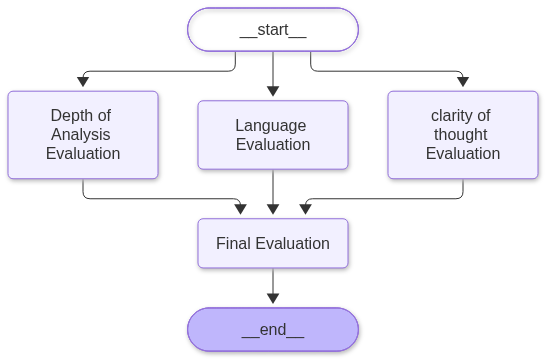

In [29]:
workflow

In [17]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from pydantic import BaseModel, Field
from typing import TypedDict, Annotated
from dotenv import load_dotenv
import operator

In [10]:
load_dotenv()

True

In [16]:
# make a structured ouput model uisng with_structured_output so we have to make a modelthat supports structured output otherwise we have to use parsers
model = ChatGroq(model='openai/gpt-oss-20b')

# make a schema
class EvaluationSchema(BaseModel):
    feedback: str = Field(description='detailed feedback for the essay')
    score: int = Field(description='integer score for the essay ranges from 0 to 1', ge=0, le=10)

# default method for structured output is function calling and it is giving error as our model by groq internally causes some fault,
#  so we will use method='json_schema, it uses Groq's dedicated Structured Outputs API
structured_model = model.with_structured_output(EvaluationSchema, method='json_schema')


In [21]:
# define state
class EssayState(TypedDict):
    essay: str
    language_feedback: str
    analysis_feedback: str
    clarity_feedback: str
    overall_feedback: str
    individual_scores: Annotated[list[int], operator.add] # this operator works as a reducer, it adds list which will be given from llms for different 
    # criterias like [8] + [4] + [7] = [8,4,7]
    avg_score: float

In [22]:
# create nodes functions
def evaluate_language(state: EssayState) -> EssayState:
    prompt = f'Evaluate the language quality of following essay and provide a feedback and assign a score out of 10 \n {state['essay']}'
    output = structured_model.invoke(prompt)
    return {
        'language_feedback': output.feedback,
        'individual_scores': [output.score]
    }

def evaluate_analysis(state: EssayState) -> EssayState:
    prompt = f'Evaluate the depth of analysis of following essay and provide a feedback and assign a score out of 10 \n {state['essay']}'
    output = structured_model.invoke(prompt)
    return {
        'analysis_feedback': output.feedback,
        'individual_scores': [output.score]
    }

def evaluate_thought(state: EssayState) -> EssayState:
    prompt = f'Evaluate the clarity of thought of following essay and provide a feedback and assign a score out of 10 \n {state['essay']}'
    output = structured_model.invoke(prompt)
    return {
        'clarity_feedback': output.feedback,
        'individual_scores': [output.score]
    }

def final_evaluation(state: EssayState) -> EssayState:

    # summarized feedback -> 
    prompt = f''' based on the following feedbacks create a summarized feedback \n language feedback -> {state['language_feedback']} \n depth of
    analysis feedback -> {state['analysis_feedback']} \n clarity of thought feedback -> {state['clarity_feedback']} '''
    # we will use a normal model here, bcs structured model may generate a score too
    overall_feedback = model.invoke(prompt).content

    # avg score ->
    avg_score = sum(state['individual_scores'])/len(state['individual_scores'])

    return {
        'overall_feedback': overall_feedback,
        'avg_score': avg_score
    }


In [28]:
# define graph
graph = StateGraph(EssayState)

# define nodes
graph.add_node('Language Evaluation', evaluate_language)
graph.add_node('clarity of thought Evaluation', evaluate_thought)
graph.add_node('Depth of Analysis Evaluation', evaluate_analysis)
graph.add_node('Final Evaluation', final_evaluation)

# define edges
graph.add_edge(START, 'Language Evaluation')
graph.add_edge(START, 'clarity of thought Evaluation')
graph.add_edge(START, 'Depth of Analysis Evaluation')

graph.add_edge('Language Evaluation', 'Final Evaluation')
graph.add_edge('clarity of thought Evaluation', 'Final Evaluation')
graph.add_edge('Depth of Analysis Evaluation', 'Final Evaluation')

graph.add_edge('Final Evaluation', END)

# compile the graph
workflow = graph.compile()

In [32]:
# sample essay to test
essay = '''
Impact of Artificial Intelligence on Education
Artificial Intelligence (AI) is transforming the education sector by making learning more personalized, accessible, and efficient. Traditional education follows a common teaching approach for all students, but AI allows learning experiences to be customized according to individual needs and learning speeds.

One of the major benefits of AI in education is personalized learning. AI-powered platforms can analyze a student's performance, identify weak areas, and recommend suitable study materials. This helps students focus on topics where they need improvement. Additionally, AI chatbots and virtual tutors can provide instant answers to questions, making learning possible beyond classroom hours.

AI also helps teachers by automating repetitive tasks such as grading assignments, tracking attendance, and preparing performance reports. This allows teachers to spend more time interacting with students and improving their teaching methods.

However, AI in education also has some challenges. Excessive dependence on AI tools may reduce students' critical thinking and problem-solving abilities. Privacy is another concern because educational platforms collect large amounts of student data. Moreover, not every student has access to reliable internet connections or modern devices, which can create inequality.

In conclusion, AI has the potential to improve education significantly, but it should be used as a supporting tool rather than a replacement for teachers. A balanced approach that combines human guidance with AI technology can create a more effective and inclusive learning environment.
'''

In [31]:
initial_state = {'essay' : essay}
final_state = workflow.invoke(initial_state)
final_state

{'essay': "\nImpact of Artificial Intelligence on Education\nArtificial Intelligence (AI) is transforming the education sector by making learning more personalized, accessible, and efficient. Traditional education follows a common teaching approach for all students, but AI allows learning experiences to be customized according to individual needs and learning speeds.\n\nOne of the major benefits of AI in education is personalized learning. AI-powered platforms can analyze a student's performance, identify weak areas, and recommend suitable study materials. This helps students focus on topics where they need improvement. Additionally, AI chatbots and virtual tutors can provide instant answers to questions, making learning possible beyond classroom hours.\n\nAI also helps teachers by automating repetitive tasks such as grading assignments, tracking attendance, and preparing performance reports. This allows teachers to spend more time interacting with students and improving their teaching